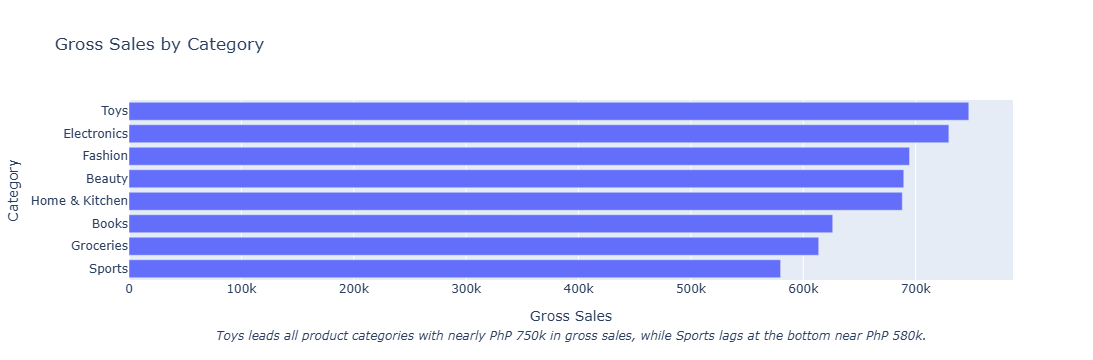

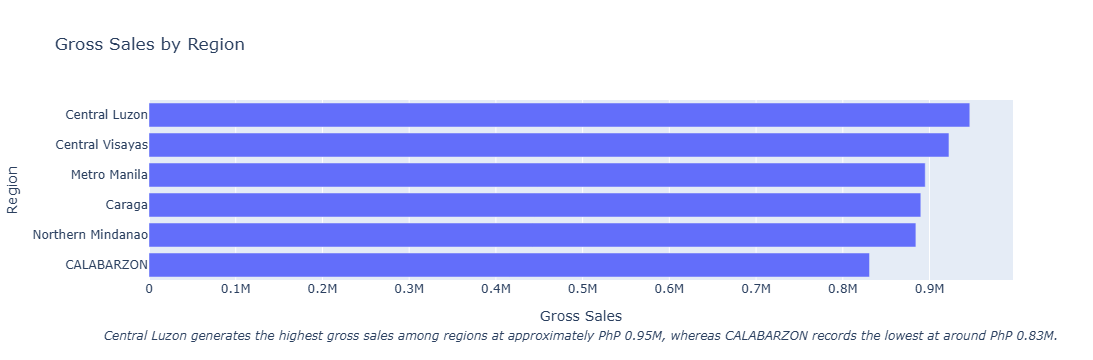

In [31]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

sales = pd.read_csv("sales_analysis.csv")
orders = pd.read_csv("order_summary.csv")

fulfilled = sales[sales["order_status"].isin(["Completed","Shipped"])]

# 1. Gross Sales by Category
category_sales_df = (
    fulfilled
    .groupby(
        "category_clean",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values("gross_sales")
)

fig = px.bar(
    category_sales_df,
    x="gross_sales",
    y="category_clean",
    orientation="h",
    title="Gross Sales by Category",
    labels={
        "gross_sales": "Gross Sales",
        "category_clean": "Category"
    }
)

# Add a caption/note at the bottom using annotations
fig.update_layout(
    annotations=[
        dict(
            text="<i>Toys leads all product categories with nearly PhP 750k in gross sales, while Sports lags at the bottom near PhP 580k.</i>",
            showarrow=False,
            xref="paper", 
            yref="paper",
            x=0.5, 
            y=-0.25,
            xanchor="center", 
            yanchor="top",
            font=dict(size=12)
        )
    ]
)

fig.show()


# 2. Gross Sales by Region
region_sales_df = (
    fulfilled
    .groupby(
        "region_name",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values("gross_sales")
)

fig = px.bar(
    region_sales_df,
    x="gross_sales",
    y="region_name",
    orientation="h",
    title="Gross Sales by Region",
    labels={
        "gross_sales": "Gross Sales",
        "region_name": "Region"
    }
)


# Add a caption/note at the bottom using annotations
fig.update_layout(
    annotations=[
        dict(
            text="<i>Central Luzon generates the highest gross sales among regions at approximately PhP 0.95M, whereas CALABARZON records the lowest at around PhP 0.83M.</i>",
            showarrow=False,
            xref="paper", 
            yref="paper",
            x=0.5, 
            y=-0.25,
            xanchor="center", 
            yanchor="top",
            font=dict(size=12)
        )
    ]
)

fig.show()

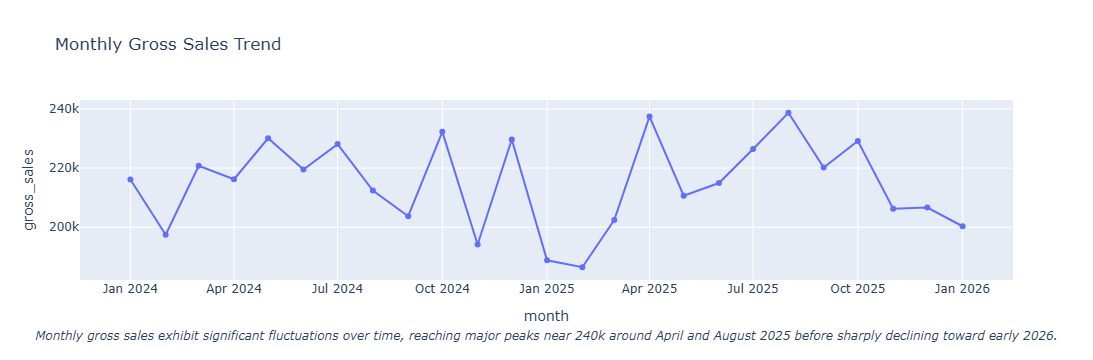

In [32]:
# 2.
# Create a line chart for monthly sales.

monthly_df = (
    fulfilled
    .groupby(
        "month",
        as_index=False
    )["gross_sales"]
    .sum()
    .sort_values("month")
)

fig = px.line(
    monthly_df,
    x="month",
    y="gross_sales",
    markers=True,
    title="Monthly Gross Sales Trend"
)

# Add a caption/note at the bottom using annotations
fig.update_layout(
    annotations=[
        dict(
            text="<i>Monthly gross sales exhibit significant fluctuations over time, reaching major peaks near 240k around April and August 2025 before sharply declining toward early 2026.</i>",
            showarrow=False,
            xref="paper", 
            yref="paper",
            x=0.5, 
            y=-0.25,
            xanchor="center", 
            yanchor="top",
            font=dict(size=12)
        )
    ]
)

fig.show()

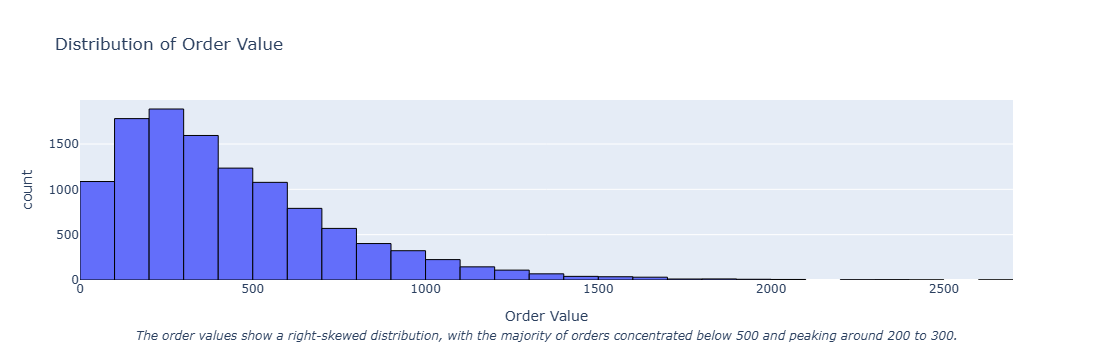

In [34]:
# 3.
# Create a histogram or box plot for order value.

fig = px.histogram(
    orders,
    x="order_value",
    nbins=30,
    title="Distribution of Order Value",
    labels={
        "order_value": "Order Value",
        "count": "Number of Orders"
    }
)

# Customize visual elements to match matplotlib's aesthetic (black bar borders)
fig.update_traces(
    marker_line_color="black",
    marker_line_width=1
)

# Add key analysis note as a bottom caption
fig.update_layout(
    annotations=[
        dict(
            text="<i>The order values show a right-skewed distribution, with the majority of orders concentrated below 500 and peaking around 200 to 300.</i>",
            showarrow=False,
            xref="paper",
            yref="paper",
            x=0.5,
            y=-0.25,
            xanchor="center",
            yanchor="top",
            font=dict(size=12)
        )
    ]
)

fig.show()

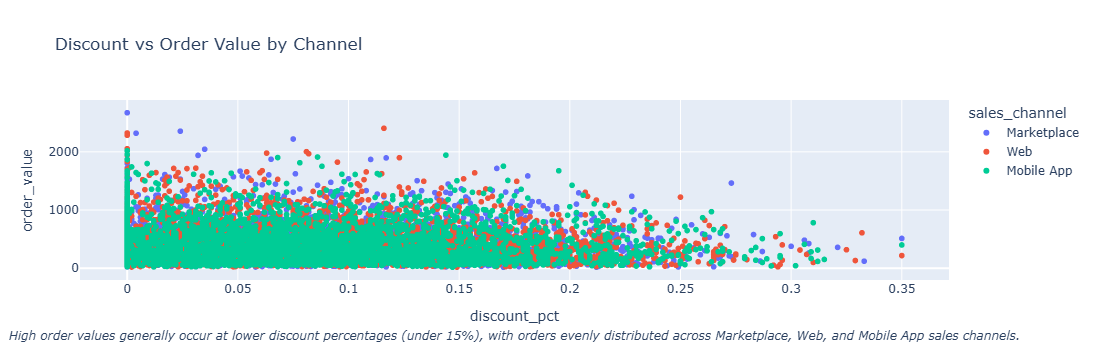

In [36]:
# 4.
# Recreate one chart with Plotly and test hover interaction.
fig = px.scatter(
    orders,
    x="discount_pct",
    y="order_value",
    color="sales_channel",
    hover_data=["order_id", "region_name"],
    title="Discount vs Order Value by Channel"
)

# Add key analysis note as a bottom caption
fig.update_layout(
    annotations=[
        dict(
            text="<i>High order values generally occur at lower discount percentages (under 15%), with orders evenly distributed across Marketplace, Web, and Mobile App sales channels.</i>",
            showarrow=False,
            xref="paper",
            yref="paper",
            x=0.5,
            y=-0.25,
            xanchor="center",
            yanchor="top",
            font=dict(size=12)
        )
    ]
)

fig.show()

In [15]:
# 5.
# Compute four dashboard KPIs: Total Sales, Orders, AOV, Top Category.
fulfilled = sales[sales["order_status"].isin(["Completed", "Shipped"])]
total_sales = fulfilled["gross_sales"].sum()
order_count = fulfilled["order_id"].nunique()
aov = orders["order_value"].mean()
top_category = (
    fulfilled.groupby("category_clean")["gross_sales"]
    .sum().idxmax()
)

In [ ]:
# 6.
# Write one sentence of interpretation below each chart.
# OUTPUT: CREATED IN EACH CHART

# 7.
# Save the code because Day 6 will place these components inside Streamlit.